# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


cleaned_airbnb_data_7.csv not found. Loading backup dataset from GitHub...
Dataset shape: (459, 77)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,host_url,host_name,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20250804133828,2025-08-04,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://www.airbnb.com/users/show/4621559,Kenneth,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,3820211,https://www.airbnb.com/rooms/3820211,20250804133828,2025-08-04,city scrape,Funky Urban Gem: Prime Central Location - Park...,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,5651579,https://www.airbnb.com/rooms/5651579,20250804133828,2025-08-04,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",The neighborhood is very eclectic. We have a v...,https://www.airbnb.com/users/show/29288920,Gregg,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,6623339,https://www.airbnb.com/rooms/6623339,20250804133828,2025-08-04,city scrape,Bright & Cozy City Stay · Top Location + Parking!,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,9005989,https://www.airbnb.com/rooms/9005989,20250804133828,2025-08-04,city scrape,"Studio in The heart of Center SQ, in Albany NY",(21 years of age or older ONLY) NON- SMOKING.....,"There are many shops, restaurants, bars, museu...",https://www.airbnb.com/users/show/17766924,Sugey,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. The dataset includes information about Airbnb listings, such as property descriptions, locations, prices, room types, availability, and host information. This data can help us understand what factors influence listing prices and how hosts can make better pricing decisions.

2. The dataset contains 459 rows and 77 columns. Each row represents an individual Airbnb listing, while the columns contain different characteristics and information about each property.

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

Dropped columns: ['id', 'listing_url', 'scrape_id', 'last_scraped', 'name', 'description', 'neighborhood_overview', 'host_url', 'host_name']
Remaining columns shape: (459, 68)


,source,host_since,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,city scrape,2013-01-07,"New York, NY",I am a real down to earth & cool person.,NaN,NaN,50%,f,https://a0.muscache.com/im/users/4621559/profi...,https://a0.muscache.com/im/users/4621559/profi...,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,city scrape,2014-08-07,"Albany, NY","Hello! I’m a proud resident of Albany, NY, whe...",within an hour,100%,100%,t,https://a0.muscache.com/im/pictures/user/User/...,https://a0.muscache.com/im/pictures/user/User/...,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,city scrape,2015-03-13,"Albany, NY",I am an Albany native .I have lived in Ireland...,within an hour,100%,99%,f,https://a0.muscache.com/im/users/29288920/prof...,https://a0.muscache.com/im/users/29288920/prof...,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,city scrape,2014-08-07,"Albany, NY","Hello! I’m a proud resident of Albany, NY, whe...",within an hour,100%,100%,t,https://a0.muscache.com/im/pictures/user/User/...,https://a0.muscache.com/im/pictures/user/User/...,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,city scrape,2014-07-07,"Albany, NY",NaN,NaN,NaN,100%,t,https://a0.muscache.com/im/pictures/user/ae311...,https://a0.muscache.com/im/pictures/user/ae311...,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. I removed columns such as id, listing_url, scrape_id, last_scraped, name, description, and neighborhood_overview because they contain identifiers, dates, or text that aren't directly useful for our numerical regression model. Removing these columns helps simplify the dataset and focus on information that could help predict Airbnb prices.

2. Including these columns could introduce unnecessary noise and make the model more complicated. The model might identify patterns in listing IDs or descriptive information that don't actually help predict prices. This could lead to overfitting and make the predictions less reliable when applied to new listings.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

Correlation of numeric variables with price:
price                                           1.000000
accommodates                                    0.579588
beds                                            0.547032
bedrooms                                        0.499286
bathrooms                                       0.468030
estimated_revenue_l365d                         0.249488
maximum_maximum_nights                          0.122872
minimum_maximum_nights                          0.112166
maximum_nights_avg_ntm                          0.111271
availability_30                                 0.108409
availability_60                                 0.060509
availability_90                                 0.040997
calculated_host_listings_count_entire_homes     0.033206
availability_eoy                                0.032537
review_scores_value                             0.018269
maximum_nights                                  0.017992
calculated_host_listings_count             

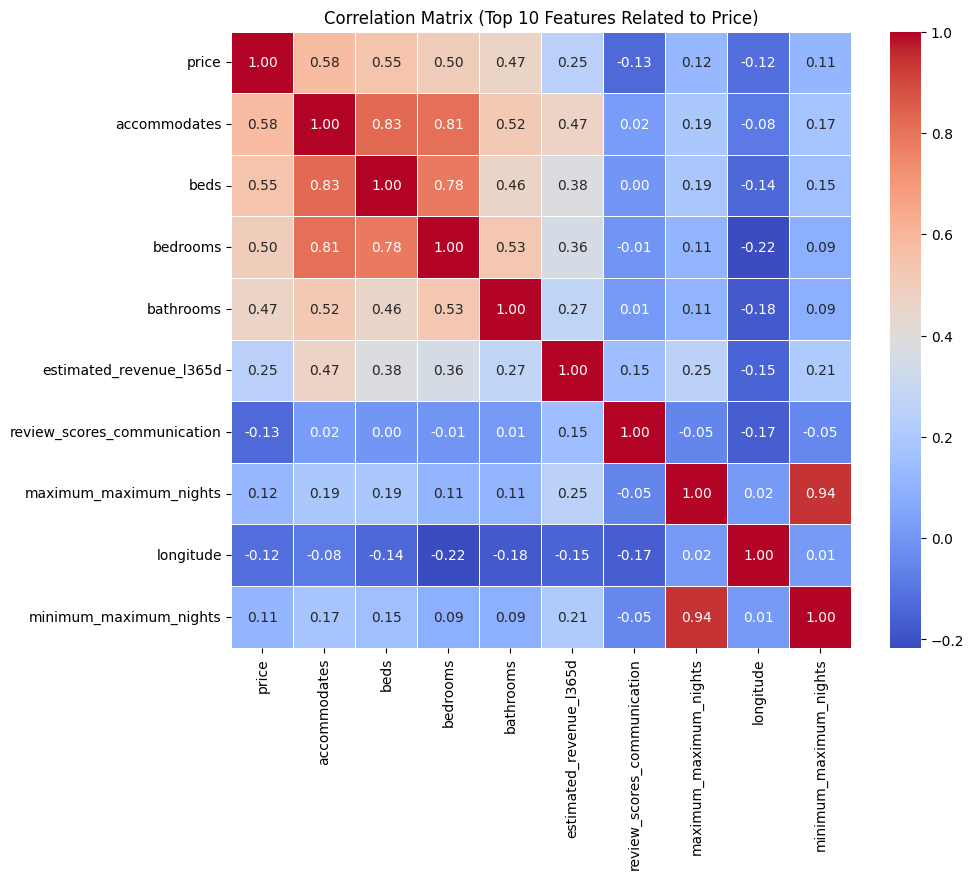

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. The strongest positive correlations with price were accommodates (0.58), beds (0.55), bedrooms (0.50), and bathrooms (0.47). This suggests that larger properties that can accommodate more guests tend to have higher prices. The strongest negative correlations were review_scores_communication (-0.13) and longitude (-0.12), although both relationships were fairly weak.

2. The most useful predictors appear to be the number of guests a property can accommodate, beds, bedrooms, and bathrooms because they have the strongest correlations with price. These variables could help predict listing prices since larger properties generally offer more space and can accommodate more people. Location may also be useful, even though its individual correlation with price is weaker.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

Target (y) shape: (459,)
Features (X) shape: (459, 40)
Features used for training: ['host_listings_count', 'host_total_listings_count', 'latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'estimated_revenue_l365d', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'instant_bookable', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms', 'calculated_host

### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. The strongest positive correlations with price were accommodates (0.58), beds (0.55), bedrooms (0.50), and bathrooms (0.47). This suggests that larger properties that can accommodate more guests tend to have higher prices. The strongest negative correlations were review_scores_communication (-0.13) and longitude (-0.12), although both relationships were fairly weak.

2. The most useful predictors appear to be the number of guests a property can accommodate, beds, bedrooms, and bathrooms because they have the strongest correlations with price. These variables could help predict listing prices since larger properties generally offer more space and can accommodate more people. Location may also be useful, even though its individual correlation with price is weaker.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



Training set size: 367
Testing set size: 92


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



Model training complete. Predictions generated for the test set.
Number of predictions: 92


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

Mean Squared Error (MSE): 8752.53
R-squared (R2) Score: -0.5595


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. My model produced an R-squared score of -0.5595, which indicates a poor fit. This means the model actually performs worse than simply predicting the average Airbnb price for every listing in the test set. It suggests that the current features and linear regression model are not capturing price variation very effectively.

2. The MSE of 8,752.53 is fairly large, indicating that the model is making significant prediction errors. To improve it, I could remove unnecessary variables, address extreme price outliers, and focus on the features that are most strongly related to price. I could also test more advanced models to see if they predict prices more accurately.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

Regression Coefficients (Sorted by Impact on Price):
                                     Feature  Coefficient
                                    latitude  -784.618582
                                   longitude  -326.230449
                 review_scores_communication  -137.706179
                         review_scores_value   135.102802
                       review_scores_checkin   -91.976509
                      minimum_nights_avg_ntm    36.504410
                      maximum_minimum_nights   -36.232262
                                   bathrooms    32.631440
                   review_scores_cleanliness   -30.029879
                      review_scores_accuracy    20.872583
                                    bedrooms   -19.742869
                                        beds    17.173759
                                accommodates    16.547959
                      review_scores_location   -13.211822
                        review_scores_rating    10.469447
                   

### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. The features with the largest positive coefficients were review_scores_value (135.10), minimum_nights_avg_ntm (36.50), and bathrooms (32.63). This suggests that higher value ratings, certain minimum-stay requirements, and having more bathrooms are associated with higher Airbnb prices when other variables are held constant.

2. Yes, some surprisingly negative coefficients were latitude (-784.62), longitude (-326.23), and review_scores_communication (-137.71). It was interesting that communication ratings had such a large negative coefficient because I would normally expect better reviews to be associated with higher prices. These results could be influenced by location differences or relationships between the predictors.

3. The results suggest that location and property characteristics are important factors to consider when pricing Airbnb listings. Hosts could use this information to compare their properties with similar listings and understand which features are associated with higher prices. However, since the model has a negative R-squared, I would be cautious about using these coefficients to make pricing decisions without improving the model first.


## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

=== Baseline Model (All Features) ===
MSE: 8752.53
R-squared (R2): -0.5595

=== Refined Model (Top 5 Features) ===
MSE: 6401.81
R-squared (R2): -0.1406


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. I kept latitude, longitude, review scores for communication, review scores for value, and review scores for check-in. These five features had the largest absolute coefficients in my original regression model. I chose them to see whether focusing on fewer variables would improve price predictions.

2. Yes, the refined model performed better than the original. The MSE decreased from 8,752.53 to 6,401.81, and the R-squared improved from -0.5595 to -0.1406. This suggests that removing some of the less useful variables helped reduce prediction errors. However, the negative R-squared shows that the model still needs improvement.

3. I would recommend the refined model over the original because it has a lower MSE and a better R-squared value. It also uses only five features, making it easier to explain to Airbnb hosts and business stakeholders. However, I wouldn't recommend using it for actual pricing decisions yet because its predictive accuracy is still relatively poor.

4. This assignment connects to my goal of using data analytics to solve real-world business problems and make better decisions. By comparing two regression models, I was able to see how selecting different features can affect prediction accuracy. It also helped me practice interpreting results and communicating them in a way that business stakeholders can understand.


## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. My model helped answer which Airbnb listing characteristics are most closely associated with nightly prices and how accurately those prices can be predicted. It showed that location and review scores may play a role in pricing, although the model still struggled to make accurate predictions.

2. I would recommend that Airbnb hosts pay attention to their property's location, guest capacity, and customer reviews when setting prices. Hosts should also compare their listings with similar properties in the area to make more informed pricing decisions. Since my model wasn't very accurate, I wouldn't recommend relying on its predictions alone.

3. I could improve the model by removing extreme price outliers, standardizing the features, and including more relevant information about each property. I could also try models like Random Forest or Gradient Boosting to see if they produce more accurate predictions. This could make the model more useful for Airbnb hosts.

4. This assignment connects to my goal of using data analytics to solve real-world business problems and make better decisions. By building and comparing regression models, I learned how to evaluate predictions, identify important variables, and explain the results from a business perspective. It also showed me that improving a model takes more than just removing variables.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"